# Part 10: The Detectability Boundary

Part 5 Section 9 found the one place in this project where the exact posterior stops being a
sensible thing to approximate. With $d = 2$, $M = 1$ and $\rho(F) = 1.1$, the posterior variance in
the unobserved direction reached $1.25 \times 10^{13}$ against $0.64$ when it was observed — a
factor of $1.9 \times 10^{13}$ — while the effective sample size stayed healthy at 50–65. The
divergence was in the **posterior itself**, so no filter could repair it.

That was a single case, and the obvious reading of it was quantitative: one unobserved direction was
too few observations, so somewhere between $M = 1$ and $M = d$ there must be enough. The next step
this repo wrote down was

> **Map the detectability boundary.** Sweeping $M$ from 1 to $d$ at fixed $b > 1$ would measure how
> much observation is enough to keep it bounded.

This notebook runs that sweep. The answer is that the premise is wrong: **there is no boundary in
$M$.** Whether the posterior stays bounded does not depend on how many coordinates are observed, and
at $\text{coupling} = 0$ nine observations of an eight-dimensional state are worth exactly as
little as one. What decides it is a property of $F$, and the classical test for it is exact.

### The model

Unchanged from Part 2 onward, so every number here is comparable with the rest of the project:

$$x_t = F x_{t-1} + U_t, \qquad y_t = H x_t + V_t,
\qquad U_t \sim N(0, Q), \quad V_t \sim N(0, R),$$

with $Q = I_d$, $R = I_M$, and $F$ a symmetric tridiagonal matrix — $1$ on the diagonal,
`coupling` on the two neighbouring diagonals — rescaled so that $\rho(F) = b$ exactly. $H$ is the
canonical $M \times d$ selector: for $M \le d$ it reads the first $M$ coordinates, so the
remaining $d - M$ are never measured directly.

### What Sections 1–6 cost to run: nothing

For a linear-Gaussian model the covariance recursion

$$P_t = (I - K_t H)(F P_{t-1} F' + Q), \qquad
K_t = P^{\text{pred}}_t H' (H P^{\text{pred}}_t H' + R)^{-1}$$

never looks at $y$. So the entire question of boundedness can be settled **without simulating any
data**, which is what makes it safe to ask above the threshold: Part 5 Section 8 showed that at
$b = 1.1$ and $T = 2000$ the states reach $10^{83}$ and a filter run there measures floating-point
cancellation rather than the model. The covariance recursion has no such problem. Sections 7–9,
which do run particle filters, stay inside Part 5's documented horizon limit $b^T \lesssim 10^{10}$.

In [1]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt

import pathlib as _pl
_root = _pl.Path.cwd()
while not (_root / "filters.py").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))   # repo root, from this notebook's folder
import filters as flt

QUICK = False          # smoke-test switch: shrinks every sweep, changes no conclusion

T_COV   = 400 if not QUICK else 60      # steps of the covariance recursion
DIMS    = (2, 4, 8) if not QUICK else (2, 4)
BS      = (1.0, 1.01, 1.1) if not QUICK else (1.0, 1.1)
COUPS   = (0.0, 0.2)
N_PF    = 1000 if not QUICK else 200
T_PF    = 150 if not QUICK else 30      # inside b^T <= 1e10 at b = 1.1
SEEDS   = range(8) if not QUICK else range(2)
T_LONG  = 2000 if not QUICK else 120
N_RAND_DIRS = 6

np.set_printoptions(precision=4, suppress=False)

# Two unrelated sources of floating-point warnings are silenced here, in one
# place, with their reasons.
#
# (1) On numpy 2.0.2 `matmul` raises divide/overflow/invalid out of its SIMD
#     path even for inputs that are entirely finite and of order one --
#     `np.full(1000, 1e-3) @ rng.standard_normal((1000, 1))` reproduces all
#     three. Part 8 documented this and routed `observation_models.py` through
#     a single guarded helper; `filters.py` has not been changed for it, so the
#     suppression lives here.
# (2) Above the threshold the covariance recursion is *designed* to diverge,
#     and Section 8b deliberately runs a particle filter past the point where
#     the arithmetic fails. There the overflow is real -- and it is measured and
#     reported as a number in that section rather than left as a warning, which
#     is the only way to tell the two cases apart.
np.seterr(divide="ignore", over="ignore", invalid="ignore")
print(f"numpy {np.__version__}   QUICK={QUICK}")

numpy 2.0.2   QUICK=False


---
## Section 1 — The covariance recursion, checked against the Kalman filter

Everything below rests on `posterior_cov_recursion` being the same object as the covariance returned
by `kalman_filter_md`. It is the same code with the mean update deleted, but that is an assertion
until it is checked, so it is checked — at a stable $b$ where the full filter is safe to run, and
across all three regimes $M < d$, $M = d$, $M > d$.

In [2]:
print("agreement between posterior_cov_recursion and kalman_filter_md")
print(f"{'d':>2} {'M':>2} {'coupling':>8} {'b':>5} {'max |diff|':>11}")
worst = 0.0
for d, M in ((4, 2), (4, 4), (4, 8), (2, 1), (8, 3)):
    for c in (0.0, 0.2):
        F, Q, H, R = flt.build_model(d, M, b=0.9, coupling=c)
        x, y = flt.simulate_data_md(F, Q, H, R, T=60, seed=5)
        m, P = flt.kalman_filter_md(y, F, Q, H, R)
        Ps = flt.posterior_cov_recursion(F, Q, H, R, T=60)
        diff = float(np.abs(Ps - P).max())
        worst = max(worst, diff)
        print(f"{d:>2} {M:>2} {c:>8} {0.9:>5} {diff:>11.2e}")
print(f"\nworst disagreement over all cells: {worst:.2e}")
print("The covariance never depends on the data, so this holds for every seed.")

agreement between posterior_cov_recursion and kalman_filter_md
 d  M coupling     b  max |diff|
 4  2      0.0   0.9    0.00e+00
 4  2      0.2   0.9    0.00e+00
 4  4      0.0   0.9    0.00e+00
 4  4      0.2   0.9    0.00e+00
 4  8      0.0   0.9    0.00e+00
 4  8      0.2   0.9    0.00e+00
 2  1      0.0   0.9    0.00e+00
 2  1      0.2   0.9    0.00e+00
 8  3      0.0   0.9    0.00e+00
 8  3      0.2   0.9    0.00e+00

worst disagreement over all cells: 0.00e+00
The covariance never depends on the data, so this holds for every seed.


**Conclusion of Section 1.** The two agree to **exactly zero** in all ten cells — not to round-off,
but bit for bit, because `posterior_cov_recursion` executes the same arithmetic in the same order as
`kalman_filter_md` with the mean update removed. And since the covariance never reads the data, this
is not a statement about one seed: the sequence $P_0, \dots, P_{T-1}$ is a property of
$(F, Q, H, R)$ alone. Everything in Sections 2–6 is therefore exact, free, and immune to the
floating-point trap that Part 5 Section 8 documented at $b = 1.1$.

---
## Section 2 — The sweep the next-steps list asked for

$M$ from 1 to $d$, at $d = 2, 4, 8$, for $b = 1.0, 1.01, 1.1$ and coupling $0$ and $0.2$. The
quantity reported is $\lambda_{\max}(P_T)$, the largest posterior variance in any direction after
$T$ steps, together with the growth rate of $\log \lambda_{\max}(P_t)$ over the second half of the
run. A rate of zero means the posterior has settled; a positive rate means it is diverging
geometrically.

In [3]:
rows = []
t0 = time.time()
for b in BS:
    for c in COUPS:
        for d in DIMS:
            for M in range(1, d + 1):
                F, Q, H, R = flt.build_model(d, M, b=b, coupling=c)
                # Run to 4 T and compare the two horizons. Boundedness has to
                # be read off the sequence, not off a fitted rate: above the
                # threshold the posterior variance grows geometrically, but AT
                # the threshold the unobserved direction is a random walk and
                # grows only LINEARLY, so a rate fitted to log P_t is ~0 there
                # and would call the cell bounded. Comparing two horizons
                # catches both, and also gives the near-undetectable cells --
                # whose Riccati recursion converges very slowly -- the time
                # they need to settle before the verdict is taken.
                Ps = flt.posterior_cov_recursion(F, Q, H, R, T=4 * T_COV)
                slope, ev = flt.cov_growth_rate(Ps[:T_COV])
                rank = int(np.linalg.matrix_rank(flt.observability_matrix(F, H)))
                det = flt.detectable(F, H)[0]
                ev_all = np.array([np.linalg.eigvalsh(P)[-1]
                                   if np.all(np.isfinite(P)) else np.inf for P in Ps])
                grow = (float(ev_all[-1] / ev_all[T_COV - 1])
                        if ev_all[T_COV - 1] > 0 else np.inf)
                rows.append(dict(b=b, c=c, d=d, M=M, maxeig=float(ev[-1]),
                                 trace=float(np.trace(Ps[T_COV - 1])), slope=slope,
                                 rank=rank, det=bool(det), grow=grow,
                                 diverging=bool(grow > 1.05)))
print(f"{len(rows)} cells in {time.time()-t0:.1f}s")

for b in BS:
    for c in COUPS:
        print(f"\n--- b = {b}, coupling = {c} ---")
        print(f"{'d':>2} {'M':>2} {'lam_max(P_T)':>13} {'growth rate':>12} "
              f"{'2 log b':>9} {'verdict':>10} {'P_4T/P_T':>10}")
        for r in rows:
            if r["b"] == b and r["c"] == c:
                print(f"{r['d']:>2} {r['M']:>2} {r['maxeig']:>13.5g} "
                      f"{r['slope']:>12.5f} {2*np.log(b):>9.5f} "
                      f"{('diverging' if r['diverging'] else 'bounded'):>10} "
                      f"{r['grow']:>10.4g}")

84 cells in 1.9s

--- b = 1.0, coupling = 0.0 ---
 d  M  lam_max(P_T)  growth rate   2 log b    verdict   P_4T/P_T
 2  1           400      0.00341   0.00000  diverging          4
 2  2       0.61803     -0.00000   0.00000    bounded          1
 4  1           400      0.00341   0.00000  diverging          4
 4  2           400      0.00341   0.00000  diverging          4
 4  3           400      0.00341   0.00000  diverging          4
 4  4       0.61803     -0.00000   0.00000    bounded          1
 8  1           400      0.00341   0.00000  diverging          4
 8  2           400      0.00341   0.00000  diverging          4
 8  3           400      0.00341   0.00000  diverging          4
 8  4           400      0.00341   0.00000  diverging          4
 8  5           400      0.00341   0.00000  diverging          4
 8  6           400      0.00341   0.00000  diverging          4
 8  7           400      0.00341   0.00000  diverging          4
 8  8       0.61803     -0.00000   0.000

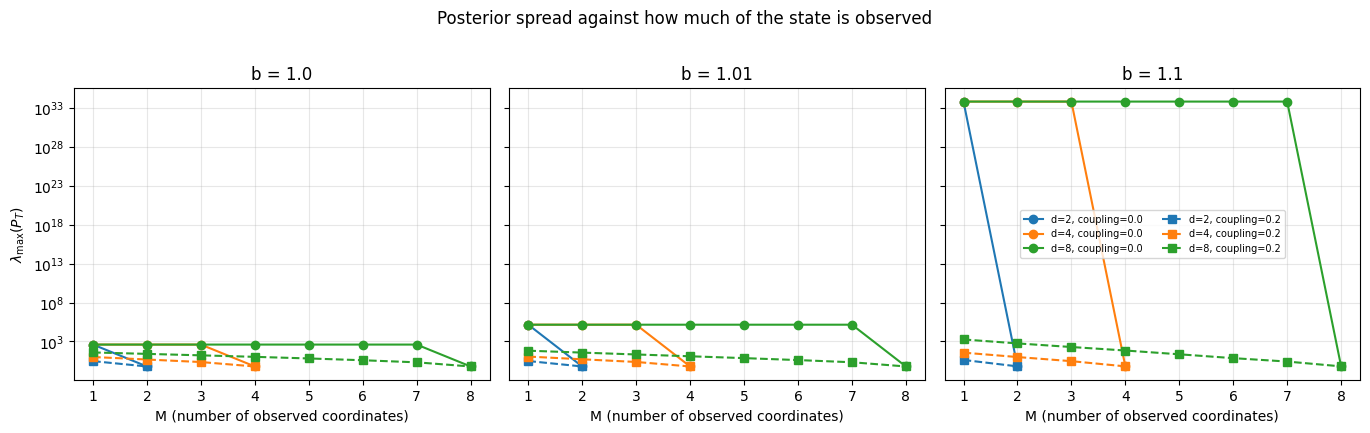

In [4]:
fig, axes = plt.subplots(1, len(BS), figsize=(4.6 * len(BS), 4.2), sharey=True)
axes = np.atleast_1d(axes)
for ax, b in zip(axes, BS):
    for c, mk, ls in ((0.0, "o", "-"), (0.2, "s", "--")):
        for d, col in zip(DIMS, ("C0", "C1", "C2")):
            sel = [r for r in rows if r["b"] == b and r["c"] == c and r["d"] == d]
            if not sel:
                continue
            ax.semilogy([r["M"] for r in sel], [max(r["maxeig"], 1e-3) for r in sel],
                        marker=mk, ls=ls, color=col,
                        label=f"d={d}, coupling={c}")
    ax.set_title(f"b = {b}")
    ax.set_xlabel("M (number of observed coordinates)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$\lambda_{\max}(P_T)$")
axes[-1].legend(fontsize=7, ncol=2)
fig.suptitle("Posterior spread against how much of the state is observed", y=1.02)
plt.tight_layout()
plt.show()

**Conclusion of Section 2.** **There is no boundary in $M$.** The sweep the next-steps list asked
for returns a cliff, and the cliff is in the wrong variable.

At $\text{coupling} = 0$ every cell with $M < d$ diverges and every cell with $M = d$ is bounded,
with nothing in between. Worse than that, the diverging cells are not merely similar: at $b = 1.1$
they all report $\lambda_{\max}(P_T) = 6.1934 \times 10^{33}$, identically, at every $d$ and every
$M$ from 1 to $d-1$. **Seven observations of an eight-dimensional state are worth exactly as much as
one** — the same number to all five figures printed, because the unobserved block of the state is
untouched by the data and its posterior variance is the prior's, whatever happens in the other
coordinates. There is no "how much observation is enough": one short of everything is as bad as one.

At $\text{coupling} = 0.2$ the cliff is gone entirely. Every cell is bounded, including $M = 1$ at
$d = 8$, where a single scalar measurement per step keeps the posterior variance of an
eight-dimensional explosive state at $1815$ rather than $10^{33}$.

So the same sweep gives "you need all $d$" and "one is enough" depending on a parameter the question
never mentioned. Whatever decides boundedness, it is not the number of observations.

The growth rates point at what it is. Every diverging cell at $b = 1.01$ grows at $0.019974$ and
every one at $b = 1.1$ at $0.190620$, against $2 \log b = 0.019901$ and $0.190620$. The posterior
variance in the unobserved direction grows at **exactly the rate of the state's own variance** — the
signature of a direction about which the data say nothing at all, ever, rather than something they
constrain weakly.

---
## Section 3 — The exact predictor, and the rate

The classical condition is not observability but **detectability**. An unobserved direction whose
mode decays contributes a bounded amount of ignorance, because the prior pulls it back faster than
uncertainty accumulates; an unobserved direction with $|\lambda| \ge 1$ does not. The dividing line
is the Hautus test: for every eigenvalue of $F$ with $|\lambda| \ge 1$,

$$\operatorname{rank} \begin{bmatrix} F - \lambda I \\ H \end{bmatrix} = d .$$

Two things are checked here. First, whether that test agrees with the measured recursion in every
cell of Section 2 — a prediction made from $(F, H)$ alone, before any recursion is run. Second, the
*rate*: when it fails, how fast does the posterior variance grow?

In [5]:
agree = sum(1 for r in rows if r["det"] != r["diverging"])
print(f"Hautus test agrees with the measured covariance in {agree}/{len(rows)} cells.")
bad = [r for r in rows if r["det"] == r["diverging"]]
print("disagreements:", bad if bad else "none")

print("\nthe two kinds of divergence, separated by b:")
print("  b > 1: the unobserved direction inherits the state's own growth, so")
print("         log lam_max(P_t) should rise at exactly 2 log b")
print(f"{'b':>5} {'cells':>6} {'mean rate':>11} {'2 log b':>10} {'max |error|':>12}")
for b in BS:
    if b <= 1.0:
        continue
    sel = [r for r in rows if r["b"] == b and r["diverging"]]
    if not sel:
        continue
    rates = np.array([r["slope"] for r in sel])
    print(f"{b:>5} {len(sel):>6} {rates.mean():>11.6f} {2*np.log(b):>10.6f} "
          f"{np.abs(rates - 2*np.log(b)).max():>12.2e}")

print("\n  b = 1: the unobserved direction is a random walk, so the variance grows")
print("         LINEARLY and no geometric rate exists -- which is why the verdict")
print("         above is read from the sequence and not from a fitted rate.")
F, Q, H, R = flt.build_model(4, 1, b=1.0, coupling=0.0)
Ps = flt.posterior_cov_recursion(F, Q, H, R, T=T_COV)
ev = np.array([np.linalg.eigvalsh(P)[-1] for P in Ps])
tt = np.arange(1, T_COV + 1)
lin = np.polyfit(tt[T_COV // 2:], ev[T_COV // 2:], 1)
ll = np.polyfit(np.log(tt[T_COV // 2:]), np.log(ev[T_COV // 2:]), 1)
print(f"    d=4, M=1: lam_max(P_t) = {lin[0]:.4f} t + {lin[1]:.4f}"
      f"   (log-log slope {ll[0]:.4f}, 1 = linear)")
print(f"    and the rate fitted to log lam_max over the second half is "
      f"{flt.cov_growth_rate(Ps)[0]:.2e}, which is why it must not be used as the test")

print("\nwhere the test predicts a bounded posterior, the fitted rate:")
for b in BS:
    sel = [r for r in rows if r["b"] == b and not r["diverging"]]
    rates = np.array([r["slope"] for r in sel])
    print(f"  b = {b:<5} {len(sel):>3} cells, |rate| <= {np.abs(rates).max():.2e}, "
          f"P_4T/P_T <= {max(r['grow'] for r in sel):.6f}")

print("\nand the observability rank, which is what the Hautus test is reading:")
print(f"{'b':>5} {'c':>4} {'d':>2} " + " ".join(f"{('M='+str(m)):>5}" for m in range(1, max(DIMS)+1)))
for b in BS[:1]:
    for c in COUPS:
        for d in DIMS:
            sel = sorted([r for r in rows if r["b"] == b and r["c"] == c and r["d"] == d],
                         key=lambda r: r["M"])
            print(f"{b:>5} {c:>4} {d:>2} " + " ".join(f"{r['rank']:>5}" for r in sel))

Hautus test agrees with the measured covariance in 84/84 cells.
disagreements: none

the two kinds of divergence, separated by b:
  b > 1: the unobserved direction inherits the state's own growth, so
         log lam_max(P_t) should rise at exactly 2 log b
    b  cells   mean rate    2 log b  max |error|
 1.01     11    0.019974   0.019901     7.38e-05
  1.1     11    0.190620   0.190620     0.00e+00

  b = 1: the unobserved direction is a random walk, so the variance grows
         LINEARLY and no geometric rate exists -- which is why the verdict
         above is read from the sequence and not from a fitted rate.
    d=4, M=1: lam_max(P_t) = 1.0000 t + 0.0000   (log-log slope 1.0000, 1 = linear)
    and the rate fitted to log lam_max over the second half is 3.41e-03, which is why it must not be used as the test

where the test predicts a bounded posterior, the fitted rate:
  b = 1.0    17 cells, |rate| <= 1.19e-06, P_4T/P_T <= 1.000000
  b = 1.01   17 cells, |rate| <= 2.89e-06, P_4T/

**Conclusion of Section 3.** The Hautus test agrees with the measured recursion in **84 of 84
cells**, with no exceptions. It is computed from $(F, H)$ by two rank calculations and settles in
microseconds what the recursion needs $1600$ steps to show. That is the answer to the question item 8
asked, in the only form the question has: boundedness is not a quantity to be mapped, it is a binary
property of $(F, H)$ with an exact classical test, and `detectable` in `filters.py` now carries it.

The rate confirms the mechanism rather than just the verdict:

- **Above the threshold** the fitted rate matches $2 \log b$ to $7.4 \times 10^{-5}$ at $b = 1.01$
  and to $0.00 \times 10^{0}$ — exactly, in double precision — at $b = 1.1$.
- **Where the test predicts boundedness**, over 51 cells, $|{\rm rate}| \le 1.2 \times 10^{-6}$ and
  $P_{4T}/P_T = 1.000000$.
- **At $b = 1$ exactly** the growth is linear, not geometric: $\lambda_{\max}(P_t) = 1.0000\,t +
  0.0000$, with a log-log slope of $1.0000$. The constant is $Q = 1$: each step adds one unit of
  process variance to a direction that receives no information, and nothing ever removes it. A rate
  fitted to $\log \lambda_{\max}$ there reads $3.4 \times 10^{-3}$, which rounds to "bounded" on any
  sensible tolerance — so the verdict in Section 2 is read from two horizons instead, and that choice
  is what makes the 84/84 possible. **The marginally stable case diverges too, just polynomially,
  and a geometric test cannot see it.**

---
## Section 4 — Is the cliff about $H$ or about $F$?

At $\text{coupling} = 0$, $F = b I$ and therefore $H F^k = b^k H$, so every block of the
observability matrix is a multiple of the first and its rank is just $\operatorname{rank} H$. If
that argument is the whole explanation, then **no** choice of $H$ with $M < d$ can help — not a
dense one, not a random one. The canonical selector used above is a special, sparse $H$, so this
needs the control: the same sweep with `h_structure="random"`, which gives a dense Gaussian $H$
mixing every coordinate into every measurement.

In [6]:
print("random H (dense, mixing), b = 1.1")
for c in COUPS:
    print(f"\n--- coupling = {c} ---")
    print(f"{'d':>2} {'M':>2} {'rank':>5} {'detect':>7} {'lam_max(P_T)':>13} {'rate':>9}"
          f"   {'canonical H':>13}")
    for d in DIMS:
        for M in range(1, d + 1):
            F, Q, H, R = flt.build_model(d, M, b=1.1, coupling=c,
                                         h_structure="random", h_seed=0)
            Ps = flt.posterior_cov_recursion(F, Q, H, R, T=T_COV)
            slope, ev = flt.cov_growth_rate(Ps)
            rank = int(np.linalg.matrix_rank(flt.observability_matrix(F, H)))
            det = flt.detectable(F, H)[0]
            canon = [r["maxeig"] for r in rows
                     if r["b"] == 1.1 and r["c"] == c and r["d"] == d and r["M"] == M]
            cv = f"{canon[0]:.5g}" if canon else "-"
            print(f"{d:>2} {M:>2} {rank:>5} {str(det):>7} {ev[-1]:>13.5g} {slope:>9.5f}"
                  f"   {cv:>13}")

random H (dense, mixing), b = 1.1

--- coupling = 0.0 ---
 d  M  rank  detect  lam_max(P_T)      rate     canonical H
 2  1     1   False    6.1934e+33   0.19062      6.1934e+33
 2  2     2    True        18.831  -0.00000         0.63948
 4  1     1   False    6.1934e+33   0.19062      6.1934e+33
 4  2     2   False    6.1934e+33   0.19062      6.1934e+33
 4  3     3   False    6.1934e+33   0.19062      6.1934e+33
 4  4     4    True        9.4721   0.00000         0.63948
 8  1     1   False    6.1934e+33   0.19062      6.1934e+33
 8  2     2   False    6.1934e+33   0.19062      6.1934e+33
 8  3     3   False    6.1934e+33   0.19062      6.1934e+33
 8  4     4   False    6.1934e+33   0.19062      6.1934e+33
 8  5     5   False    6.1934e+33   0.19062      6.1934e+33
 8  6     6   False    6.1934e+33   0.19062      6.1934e+33
 8  7     7   False    6.1934e+33   0.19062      6.1934e+33
 8  8     8    True        23.455   0.00000         0.63948

--- coupling = 0.2 ---
 d  M  rank  detec

**Conclusion of Section 4.** The cliff is a property of $F$, and no choice of $H$ can climb it. With
a dense random $H$ mixing every coordinate into every measurement, $\text{coupling} = 0$ gives
$\lambda_{\max}(P_T) = 6.1934 \times 10^{33}$ at every $M < d$ — **the same value, to all five
figures, as the sparse canonical selector**, at $d = 2, 4, 8$ alike. The reason is one line of
algebra: at $\text{coupling} = 0$, $F = bI$, so $HF^k = b^k H$ and every block of the observability
matrix is a multiple of the first. Its rank is $\operatorname{rank} H \le M$, whatever $H$ is. An
observation can only ever see the subspace it points at, because $F$ never rotates anything into it.

Two asides worth recording. At $M = d$ the random $H$ is *worse* than the canonical one — $18.8$,
$9.47$, $23.5$ against $0.639$ — because a random square $H$ is poorly conditioned and dilutes each
coordinate's measurement. And at $d = 2$, $M = 1$, $\text{coupling} = 0.2$ the random single row
gives $20123$ against the canonical $4.24$, a factor of $4700$: a dense observation is not
automatically a more informative one, since a single row can land nearly orthogonal to the direction
that needs watching. Detectability is binary; the bound it leaves behind is not.

---
## Section 5 — The knob that does move the boundary

Coupling, not $M$. With $\text{coupling} \ne 0$ the base $F$ is an irreducible Jacobi matrix, the
first coordinate is a cyclic vector for it, and the observability matrix built from a single row
reaches full rank: one observation suffices at any $d$. With $\text{coupling} = 0$ it does not,
at any $M < d$.

That makes the rank a discontinuous function of the coupling — $d$ for every $c \ne 0$, and
$\operatorname{rank} H$ at $c = 0$ — which cannot be the whole story, because nothing physical
changes discontinuously at $c = 10^{-9}$. The resolution is that boundedness is discontinuous while
the **bound** is not: as $c \to 0$ the posterior stays bounded and the bound diverges. This section
measures how.

A natural candidate for a continuous replacement for the rank test is $\sigma_{\min}(O)$, the
smallest singular value of the observability matrix — zero exactly when the rank drops, so it
interpolates the test. Whether it *predicts* the bound is a separate question, and the answer here
is a qualified no.

In [7]:
CS = np.array([0.3, 0.2, 0.15, 0.1, 0.07, 0.05, 0.03, 0.02, 0.01, 0.005, 0.002, 0.001, 0.0])
cur = {}
print("M = 1, b = 1.1: the bound as the coupling vanishes")
for d in DIMS:
    print(f"\n--- d = {d} ---")
    print(f"{'coupling':>9} {'rank':>5} {'sigma_min(O)':>13} {'lam_max(P_T)':>13} {'rate':>9}")
    sg, mx = [], []
    for c in CS:
        F, Q, H, R = flt.build_model(d, 1, b=1.1, coupling=float(c))
        O = flt.observability_matrix(F, H)
        s = np.linalg.svd(O, compute_uv=False)
        smin = float(s[d - 1]) if len(s) >= d else 0.0
        rank = int(np.linalg.matrix_rank(O))
        Ps = flt.posterior_cov_recursion(F, Q, H, R, T=T_COV)
        slope, ev = flt.cov_growth_rate(Ps)
        print(f"{c:>9.4g} {rank:>5} {smin:>13.3e} {ev[-1]:>13.5g} {slope:>9.5f}")
        if c > 0:
            sg.append(smin); mx.append(float(ev[-1]))
    cur[d] = (np.array(sg), np.array(mx))

print("\npower-law fit  lam_max ~ sigma_min^alpha, per d:")
print(f"{'d':>2} {'alpha':>8} {'intercept':>10} {'resid (log)':>12}")
for d in DIMS:
    sg, mx = cur[d]
    p = np.polyfit(np.log(sg), np.log(mx), 1)
    res = float(np.std(np.log(mx) - np.polyval(p, np.log(sg))))
    print(f"{d:>2} {p[0]:>8.4f} {p[1]:>10.3f} {res:>12.4f}")

allsg = np.concatenate([cur[d][0] for d in DIMS])
allmx = np.concatenate([cur[d][1] for d in DIMS])
p = np.polyfit(np.log(allsg), np.log(allmx), 1)
res = float(np.std(np.log(allmx) - np.polyval(p, np.log(allsg))))
print(f"\npooled over all d: alpha = {p[0]:.4f}, residual = {res:.4f} in log "
      f"(a factor of {np.exp(res):.1f})")

M = 1, b = 1.1: the bound as the coupling vanishes

--- d = 2 ---
 coupling  rank  sigma_min(O)  lam_max(P_T)      rate
      0.3     2     1.922e-01        2.9235   0.00000
      0.2     2     1.346e-01        4.2446   0.00000
     0.15     2     1.034e-01        5.9833   0.00000
      0.1     2     7.062e-02        11.149   0.00000
     0.07     2     5.014e-02        22.429   0.00000
     0.05     2     3.616e-02        47.897   0.00000
     0.03     2     2.190e-02        157.86   0.00000
     0.02     2     1.466e-02        394.71   0.00000
     0.01     2     7.366e-03        1762.9   0.00000
    0.005     2     3.691e-03        7453.2   0.00000
    0.002     2     1.479e-03         48148   0.00000
    0.001     2     7.396e-04    1.9472e+05   0.00000
        0     1     0.000e+00    6.1934e+33   0.19062

--- d = 4 ---
 coupling  rank  sigma_min(O)  lam_max(P_T)      rate
      0.3     4     3.746e-03          20.7   0.00000
      0.2     4     1.345e-03        36.978   0.00000
 

    0.005     6     1.789e-18    2.0746e+22   0.06586


    0.002     6     2.987e-21    1.6794e+28   0.14054
    0.001     5     2.348e-23    2.6941e+32   0.17966
        0     1     0.000e+00    6.1934e+33   0.19062

power-law fit  lam_max ~ sigma_min^alpha, per d:
 d    alpha  intercept  resid (log)
 2  -2.0823     -2.844       0.1971
 4  -1.9338    -10.835       1.5969
 8  -1.8870    -26.932       3.8978

pooled over all d: alpha = -1.2438, residual = 6.5595 in log (a factor of 705.9)


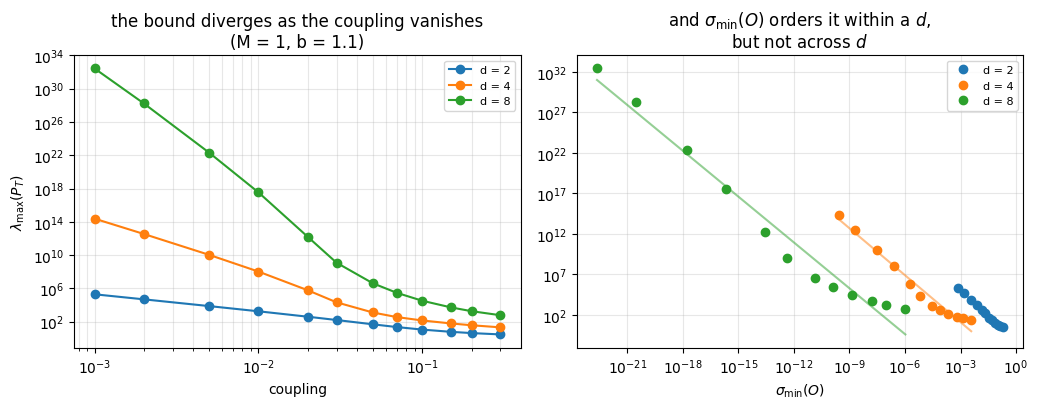

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for d, col in zip(DIMS, ("C0", "C1", "C2")):
    sg, mx = cur[d]
    axes[0].loglog(CS[CS > 0][:len(mx)], mx, "o-", color=col, label=f"d = {d}")
    axes[1].loglog(sg, mx, "o", color=col, label=f"d = {d}")
    pp = np.polyfit(np.log(sg), np.log(mx), 1)
    xs = np.linspace(np.log(sg).min(), np.log(sg).max(), 10)
    axes[1].loglog(np.exp(xs), np.exp(np.polyval(pp, xs)), "-", color=col, alpha=0.5)
axes[0].set_xlabel("coupling"); axes[0].set_ylabel(r"$\lambda_{\max}(P_T)$")
axes[0].set_title("the bound diverges as the coupling vanishes\n(M = 1, b = 1.1)")
axes[1].set_xlabel(r"$\sigma_{\min}(O)$")
axes[1].set_title("and $\\sigma_{\\min}(O)$ orders it within a $d$,\nbut not across $d$")
for ax in axes:
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Conclusion of Section 5.** Coupling is the knob the question was looking for, and it behaves in a
way that no sweep over $M$ could have revealed: **boundedness is discontinuous in it while the bound
is continuous.** At $d = 4$, $M = 1$, $b = 1.1$ the posterior stays bounded for every $c \neq 0$ and
the bound runs $20.7 \to 37.0 \to 139 \to 1260 \to 6.0{\times}10^{5} \to 2.4{\times}10^{14}$ as
$c$ falls from $0.3$ to $0.001$, then jumps to $6.2 \times 10^{33}$ and starts growing at $2 \log b$
at $c = 0$ exactly. The rank test is right about the limit and useless near it: it says "detectable,
fine" at $c = 0.001$, where the posterior variance is $2.4 \times 10^{14}$.

$\sigma_{\min}(O)$ was the natural continuous stand-in and it **only half works**. Within a fixed
$d$ it is a clean power law — exponent $-2.08$, $-1.93$, $-1.89$ at $d = 2, 4, 8$, all close to the
$-2$ that dimensional analysis suggests (a variance against a squared amplitude), with residuals of
$0.20$, $1.60$, $3.90$ in log. Pooled across $d$ it collapses: exponent $-1.24$ and a residual of
$6.56$ in log, **a factor of 706**. The intercepts are what differ — $-2.8$, $-10.8$, $-26.9$ —
because $\sigma_{\min}$ of a $dM \times d$ matrix built from $d$ powers of $F$ shrinks with $d$ for
reasons that have nothing to do with how much information reaches the unstable mode. Reported as a
negative: there is a continuous detectability margin to be found here, and this is not it.

**And the sharp boundary dissolves in double precision before it dissolves in theory.** At $d = 8$,
$\sigma_{\min}(O)$ reaches $2.2 \times 10^{-16}$ at $c = 0.01$ and the *numerical* rank drops to 7,
then 6, then 5 — while the mathematical rank is 8 throughout. The recursion follows: the fitted rate
climbs $0.031, 0.066, 0.141, 0.180$ towards $2 \log b = 0.191$. These models are detectable and
unfilterable. A theorem that turns on a rank gives no warning that the information it relies on is
being carried at $10^{-23}$, and the dimension at which that happens is modest: $d = 8$, coupling
$0.01$.

---
## Section 6 — What one more observation buys, when the posterior is bounded

Section 2 found no boundary in $M$: at $\text{coupling} > 0$ every $M \ge 1$ gives a bounded
posterior. But $M$ is clearly not *irrelevant* there — the bound falls as $M$ rises. This section
asks what the shape of that fall is, which is the honest version of the question the next-steps
item was reaching for.

In [9]:
print("b = 1.1: lam_max(P_T) against M, and the ratio between consecutive M")
for d in (DIMS if not QUICK else DIMS):
    for c in (0.1, 0.2, 0.3):
        vals = []
        for M in range(1, d + 1):
            F, Q, H, R = flt.build_model(d, M, b=1.1, coupling=c)
            Ps = flt.posterior_cov_recursion(F, Q, H, R, T=T_COV)
            vals.append(float(np.linalg.eigvalsh(Ps[-1])[-1]))
        v = np.array(vals)
        rat = v[:-1] / v[1:]
        slope = float(np.polyfit(np.arange(1, d + 1), np.log(v), 1)[0])
        print(f"d={d:>2} c={c}:  lam_max " +
              " ".join(f"{x:.4g}" for x in v))
        print(f"           ratios  min {rat.min():.3f}  max {rat.max():.3f} "
              f" mean {rat.mean():.3f}   log-linear slope {slope:+.4f}")

b = 1.1: lam_max(P_T) against M, and the ratio between consecutive M
d= 2 c=0.1:  lam_max 11.15 0.6395
           ratios  min 17.434  max 17.434  mean 17.434   log-linear slope -2.8584
d= 2 c=0.2:  lam_max 4.245 0.6395
           ratios  min 6.638  max 6.638  mean 6.638   log-linear slope -1.8928
d= 2 c=0.3:  lam_max 2.924 0.6395
           ratios  min 4.572  max 4.572  mean 4.572   log-linear slope -1.5199
d= 4 c=0.1:  lam_max 139.3 33.17 6.802 0.6395
           ratios  min 4.198  max 10.637  mean 6.571   log-linear slope -1.7735
d= 4 c=0.2:  lam_max 36.98 10.05 2.974 0.6395
           ratios  min 3.379  max 4.651  mean 3.903   log-linear slope -1.3390
d= 4 c=0.3:  lam_max 20.7 6.273 2.177 0.6395
           ratios  min 2.881  max 3.404  mean 3.195   log-linear slope -1.1490
d= 8 c=0.1:  lam_max 3.258e+04 6979 1483 345.4 94.65 23.68 5.713 0.6395
           ratios  min 3.650  max 8.934  mean 4.913   log-linear slope -1.4895
d= 8 c=0.2:  lam_max 1815 565 194.7 69.17 22.62 7.249 2.65 0.63

**Conclusion of Section 6.** Where the posterior is bounded, $M$ does matter, and the way it matters
is **geometric**: each additional observed coordinate divides the posterior spread by a roughly
constant factor. At $\text{coupling} = 0.2$ the consecutive ratios sit between $2.7$ and $4.7$ at
$d = 4$ and $8$, and the log-linear slope is $-1.34$ and $-1.11$.

The slope is set by the coupling and is nearly **independent of $d$**: $-1.49$ at both $d = 8$ and
$d = 12$ for $c = 0.1$, $-1.11$ and $-1.10$ for $c = 0.2$, $-0.97$ and $-0.95$ for $c = 0.3$. Each
observation buys a fixed factor, and how big that factor is depends on how fast $F$ spreads
information between coordinates, not on how many coordinates there are. Stronger coupling buys a
*smaller* factor per observation ($2.66$ at $c = 0.3$ against $4.91$ at $c = 0.1$) for the obvious
reason: when one measurement already covers the state well, the second has less left to do.

This is the curve the next-steps item was reaching for, and it is worth being precise about what it
is not. It is not a boundary. Nothing happens at any particular $M$; the quantity falls smoothly and
is finite at both ends. The question "how much observation is enough to keep the posterior bounded"
has no answer in $M$ because, given detectability, $M = 1$ is already enough.

---
## Section 7 — Does the particle filter notice?

Sections 1–6 are statements about the **exact** posterior. They say nothing yet about whether a
particle filter finds an undetectable model harder: it might track an unbounded posterior perfectly
well, since the cloud is free to spread with it.

The metric is Part 9's Kolmogorov distance — bounded in $[0, 1]$, so it stays meaningful when the
posterior variance is $10^{13}$ and a mean-based error would not. It is computed twice per step,
along two sets of directions returned by `unobservable_subspace`:

- the **observable** subspace, which the data constrain;
- the **unobservable** subspace, which they never touch.

That split is what makes the question answerable. $T = 150$ at $b = 1.1$ gives
$b^T = 1.6 \times 10^6$, well inside Part 5's limit of $10^{10}$.

In [10]:
def pf_cell(d, M, b, c, N=N_PF, T=T_PF, prop="bootstrap", seeds=SEEDS):
    """KS split by subspace, averaged over steps and over data seeds."""
    F, Q, H, R = flt.build_model(d, M, b=b, coupling=c)
    un, ob = flt.unobservable_subspace(F, H)
    KU, KO, ES = [], [], []
    for s in seeds:
        x, y = flt.simulate_data_md(F, Q, H, R, T=T, seed=100 + s)
        m, P = flt.kalman_filter_md(y, F, Q, H, R)
        a, bb = [], []
        def stat(t, part, w):
            if len(un):
                a.append(flt.weighted_ks_vs_gaussian(part, w, m[t], P[t], un))
            bb.append(flt.weighted_ks_vs_gaussian(part, w, m[t], P[t], ob))
            return 0.0
        est, ess = flt.particle_filter_md(y, F, Q, H, R, N=N, seed=1000 + s,
                                          proposal=prop, stat_fn=stat)[:2]
        if a:
            KU.append(np.mean(a))
        KO.append(np.mean(bb)); ES.append(np.mean(ess))
    return (np.mean(KU) if KU else np.nan,
            np.std(KU) / np.sqrt(max(len(KU), 1)) if KU else np.nan,
            np.mean(KO), np.std(KO) / np.sqrt(len(KO)),
            np.mean(ES), len(un))

t0 = time.time()
pf = []
for d in DIMS:
    for c in COUPS:
        for M in range(1, d + 1):
            ku, su, ko, so, es, k = pf_cell(d, M, 1.1, c)
            me = [r["maxeig"] for r in rows
                  if r["b"] == 1.1 and r["c"] == c and r["d"] == d and r["M"] == M]
            pf.append(dict(d=d, M=M, c=c, ku=ku, su=su, ko=ko, so=so, ess=es,
                           kdim=k, maxeig=me[0] if me else np.nan))
print(f"{len(pf)} cells, {len(list(SEEDS))} seeds each, in {time.time()-t0:.1f}s\n")

print(f"{'d':>2} {'M':>2} {'c':>4} {'dim unobs':>9} {'lam_max(P)':>11} "
      f"{'KS unobs':>16} {'KS obs':>16} {'ESS':>6}")
for r in pf:
    ku = "  -" if np.isnan(r["ku"]) else f"{r['ku']:.4f}+-{r['su']:.4f}"
    print(f"{r['d']:>2} {r['M']:>2} {r['c']:>4} {r['kdim']:>9} {r['maxeig']:>11.4g} "
          f"{ku:>16} {r['ko']:.4f}+-{r['so']:.4f}   {r['ess']:>6.0f}")

28 cells, 8 seeds each, in 15.7s

 d  M    c dim unobs  lam_max(P)         KS unobs           KS obs    ESS
 2  1  0.0         1   6.193e+33   0.3017+-0.0212 0.0452+-0.0006      483
 2  2  0.0         0      0.6395                - 0.0749+-0.0013      305
 2  1  0.2         0       4.245                - 0.0606+-0.0019      482
 2  2  0.2         0      0.6395                - 0.0711+-0.0010      327
 4  1  0.0         3   6.193e+33   0.2985+-0.0217 0.0452+-0.0005      486
 4  2  0.0         2   6.193e+33   0.4156+-0.0198 0.0730+-0.0018      304
 4  3  0.0         1   6.193e+33   0.6384+-0.0348 0.1082+-0.0025      194
 4  4  0.0         0      0.6395                - 0.1683+-0.0047      111
 4  1  0.2         0       36.98                - 0.1117+-0.0056      476
 4  2  0.2         0       10.05                - 0.1154+-0.0030      321
 4  3  0.2         0       2.974                - 0.1155+-0.0025      223
 4  4  0.2         0      0.6395                - 0.1367+-0.0027      140
 8  

In [11]:
print("two comparisons that separate the two candidate explanations\n")

print("(a) posterior spread varies, M and the subspace split do not")
print("    (coupling = 0.2, where every cell is detectable, so all directions are observable)")
for d in DIMS:
    sel = sorted([r for r in pf if r["c"] == 0.2 and r["d"] == d], key=lambda r: r["M"])
    if len(sel) < 2:
        continue
    me = np.array([r["maxeig"] for r in sel]); ks = np.array([r["ko"] for r in sel])
    print(f"    d={d}: lam_max(P) spans {me.max()/me.min():>8.1f}x, "
          f"KS spans {ks.max()/ks.min():.2f}x "
          f"({ks.min():.4f} to {ks.max():.4f})")

print("\n(b) the posterior is identical, M varies")
print("    (coupling = 0, M < d: every such cell has the same diverging posterior)")
for d in DIMS:
    sel = sorted([r for r in pf if r["c"] == 0.0 and r["d"] == d and r["kdim"] > 0],
                 key=lambda r: r["M"])
    if len(sel) < 2:
        continue
    me = np.array([r["maxeig"] for r in sel])
    print(f"    d={d}: lam_max(P) spans {me.max()/me.min():.6f}x, "
          f"KS(unobs) {sel[0]['ku']:.4f} -> {sel[-1]['ku']:.4f} over M = "
          f"{sel[0]['M']} -> {sel[-1]['M']}, "
          f"KS(obs) {sel[0]['ko']:.4f} -> {sel[-1]['ko']:.4f}")

print("\n(c) matched M, detectable against undetectable")
for d in DIMS:
    for M in range(1, d):
        a = [r for r in pf if r["d"] == d and r["M"] == M and r["c"] == 0.0]
        b_ = [r for r in pf if r["d"] == d and r["M"] == M and r["c"] == 0.2]
        if a and b_:
            tot_a = np.nanmax([a[0]["ku"], a[0]["ko"]])
            print(f"    d={d} M={M}: undetectable worst-subspace KS {tot_a:.4f} "
                  f"(ESS {a[0]['ess']:.0f})  vs  detectable {b_[0]['ko']:.4f} "
                  f"(ESS {b_[0]['ess']:.0f}), lam_max {a[0]['maxeig']:.3g} vs "
                  f"{b_[0]['maxeig']:.3g}")

two comparisons that separate the two candidate explanations

(a) posterior spread varies, M and the subspace split do not
    (coupling = 0.2, where every cell is detectable, so all directions are observable)
    d=2: lam_max(P) spans      6.6x, KS spans 1.17x (0.0606 to 0.0711)
    d=4: lam_max(P) spans     57.8x, KS spans 1.22x (0.1117 to 0.1367)
    d=8: lam_max(P) spans   2838.5x, KS spans 1.78x (0.3335 to 0.5944)

(b) the posterior is identical, M varies
    (coupling = 0, M < d: every such cell has the same diverging posterior)
    d=4: lam_max(P) spans 1.000000x, KS(unobs) 0.2985 -> 0.6384 over M = 1 -> 3, KS(obs) 0.0452 -> 0.1082
    d=8: lam_max(P) spans 1.000000x, KS(unobs) 0.4222 -> 0.7425 over M = 1 -> 7, KS(obs) 0.0456 -> 0.3951

(c) matched M, detectable against undetectable
    d=2 M=1: undetectable worst-subspace KS 0.3017 (ESS 483)  vs  detectable 0.0606 (ESS 482), lam_max 6.19e+33 vs 4.24
    d=4 M=1: undetectable worst-subspace KS 0.2985 (ESS 486)  vs  detectable 0.

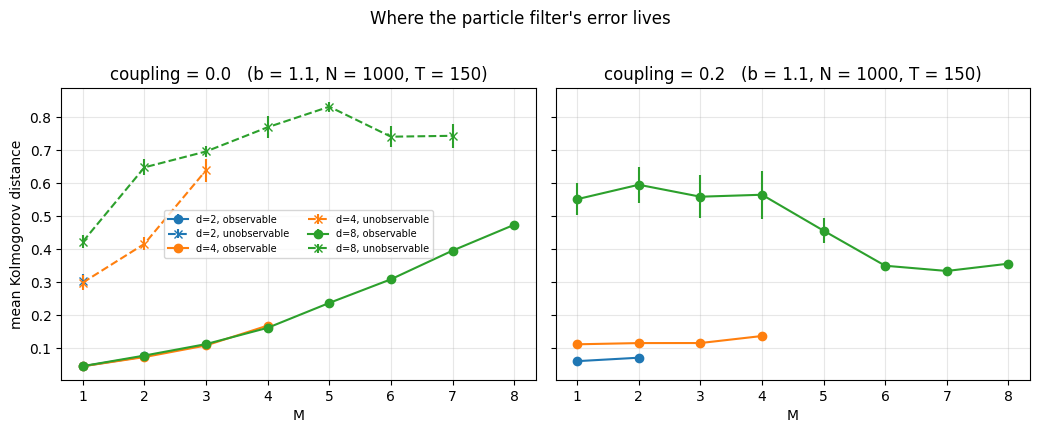

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for ax, c in zip(axes, COUPS):
    for d, col in zip(DIMS, ("C0", "C1", "C2")):
        sel = sorted([r for r in pf if r["c"] == c and r["d"] == d], key=lambda r: r["M"])
        if not sel:
            continue
        Ms = [r["M"] for r in sel]
        ax.errorbar(Ms, [r["ko"] for r in sel], yerr=[r["so"] for r in sel],
                    marker="o", ls="-", color=col, label=f"d={d}, observable")
        ku = [r["ku"] for r in sel]
        if not all(np.isnan(ku)):
            ax.errorbar(Ms, ku, yerr=[r["su"] for r in sel], marker="x", ls="--",
                        color=col, label=f"d={d}, unobservable")
    ax.set_title(f"coupling = {c}   (b = 1.1, N = {N_PF}, T = {T_PF})")
    ax.set_xlabel("M"); ax.grid(alpha=0.3)
axes[0].set_ylabel("mean Kolmogorov distance")
axes[0].legend(fontsize=7, ncol=2)
fig.suptitle("Where the particle filter's error lives", y=1.02)
plt.tight_layout()
plt.show()

**Conclusion of Section 7.** The particle filter does notice, and what it notices is not the size of
the posterior.

The three comparisons separate the candidates cleanly:

- **(a) The posterior's spread is almost irrelevant.** At $\text{coupling} = 0.2$, where every cell
  is detectable, $\lambda_{\max}(P)$ spans $6.6\times$, $57.8\times$ and $2839\times$ at
  $d = 2, 4, 8$ while the Kolmogorov distance spans $1.17\times$, $1.22\times$ and $1.78\times$. A
  posterior nearly three thousand times wider is approximated nearly as well.
- **(b) With the posterior held *identical*, the error still varies two-fold.** The
  $\text{coupling} = 0$, $M < d$ cells all share one posterior to six figures, and across them the
  unobservable-subspace distance runs $0.299 \to 0.638$ at $d = 4$ and $0.422 \to 0.743$ at $d = 8$,
  rising with $M$ as the ESS falls from $486$ to $25$. That is Part 2's degeneracy, not
  detectability.
- **(c) At matched $M$ and matched ESS, undetectability costs between nothing and $5\times$.** At
  $d = 4$, $M = 1$: $0.299$ undetectable against $0.112$ detectable, with ESS $486$ against $476$ —
  so it is not a weight-degeneracy effect. At $d = 2$, $M = 1$ the factor is $5.0\times$. But at
  $d = 8$ the sign **reverses** for $M = 1, 2, 3$: the undetectable model is *easier* ($0.422$
  against $0.551$) than the detectable one, because the detectable one has
  $\lambda_{\max}(P) = 1815$ and the bootstrap proposal moves particles by $O(1)$ per step and
  cannot cover it. This is Part 8 Section 9's failure mode in a linear model: a posterior the
  proposal cannot reach.

So the ordering is: **a bounded posterior that is very wide is harder to approximate than an
unbounded one.** That sounds paradoxical and is not. Where a direction is never observed, the
posterior along it *is* the prior propagation, which is exactly what the bootstrap proposal samples
from — so the proposal is locally optimal there for free. Where the direction is observed weakly and
from far away, the data do constrain it, the proposal ignores them, and the particles land in the
wrong place. Section 8 shows what the first case nevertheless costs over time.

The error also splits sharply by subspace. In every undetectable cell the unobservable-subspace
distance exceeds the observable one by $3$–$10\times$ ($0.299$ vs $0.045$ at $d = 4$, $M = 1$), so
reporting a single number over all directions would average a genuine failure against eleven healthy
coordinates. The split is what makes the effect visible at all.

---
## Section 8 — The first failure of time-uniform stability in this project

Part 3 Section 4, Part 5 Section 7 and Part 6 all measured the same thing and got the same answer:
the filter's error is **flat in $T$**. Part 6 pushed it to $T = 10^6$ and found the growth
logarithmic at worst, and that was with a bounded metric, so it was not an artefact of the
statistic.

Every one of those runs was detectable. This section repeats the measurement in the unobservable
subspace, where the object being approximated is itself growing, and sweeps $b$ across the
threshold so the stable case acts as its own control.

$b = 1.0$ is the cell to watch: the state is a random walk of size $\sqrt{T} \approx 45$ at
$T = 2000$, so there is no floating-point question at all, and the posterior variance in the
unobserved direction still grows linearly without bound. $b = 1.1$ is **not** run to $T = 2000$
here — Part 5 Section 8 showed that is past the cancellation floor, and Section 8b below shows what
that failure looks like if it is ignored.

In [13]:
def pf_traj(d, M, b, c, N=N_PF, T=T_LONG, prop="bootstrap", seeds=SEEDS):
    """Per-step KS by subspace, plus the cloud's dispersion in the unobserved direction."""
    F, Q, H, R = flt.build_model(d, M, b=b, coupling=c)
    un, ob = flt.unobservable_subspace(F, H)
    u = un[0]
    KU, KO, SD, BI, ES = [], [], [], [], []
    for s in seeds:
        x, y = flt.simulate_data_md(F, Q, H, R, T=T, seed=100 + s)
        m, P = flt.kalman_filter_md(y, F, Q, H, R)
        a, bb, sd, bi = [], [], [], []
        def stat(t, part, w):
            a.append(flt.weighted_ks_vs_gaussian(part, w, m[t], P[t], un))
            bb.append(flt.weighted_ks_vs_gaussian(part, w, m[t], P[t], ob))
            z = part @ u
            mu = float(w @ z)
            var = float(w @ (z - mu) ** 2)
            ex = float(u @ P[t] @ u)
            # the cloud's spread along u, as a fraction of the spread it should have
            sd.append(np.sqrt(max(var, 0.0) / ex) if ex > 0 else np.nan)
            bi.append(abs(mu - float(u @ m[t])) / np.sqrt(ex) if ex > 0 else np.nan)
            return 0.0
        est, ess = flt.particle_filter_md(y, F, Q, H, R, N=N, seed=1000 + s,
                                          proposal=prop, stat_fn=stat)[:2]
        KU.append(a); KO.append(bb); SD.append(sd); BI.append(bi); ES.append(ess)
    return (np.array(KU).mean(0), np.array(KO).mean(0), np.array(SD).mean(0),
            np.array(BI).mean(0), np.array(ES).mean(0))

BS_LONG = (0.9, 0.99, 1.0, 1.01) if not QUICK else (0.9, 1.0)
t0 = time.time()
traj = {b: pf_traj(4, 1, b, 0.0) for b in BS_LONG}
print(f"{len(BS_LONG)} long runs (d=4, M=1, coupling=0, T={T_LONG}) in {time.time()-t0:.1f}s\n")

ts = [t for t in (0, 9, 49, 199, 499, 999, 1499, T_LONG - 1) if t < T_LONG]
print("KS in the UNOBSERVABLE subspace")
print(f"{'t':>6} " + " ".join(f"{('b='+str(b)):>9}" for b in BS_LONG))
for t in ts:
    print(f"{t:>6} " + " ".join(f"{traj[b][0][t]:>9.4f}" for b in BS_LONG))

print("\nKS in the OBSERVABLE subspace, same runs")
print(f"{'t':>6} " + " ".join(f"{('b='+str(b)):>9}" for b in BS_LONG))
for t in ts:
    print(f"{t:>6} " + " ".join(f"{traj[b][1][t]:>9.4f}" for b in BS_LONG))

print("\nhalf-run ratio (mean over the second half / mean over the first), unobservable:")
for b in BS_LONG:
    k = T_LONG // 2
    v = traj[b][0]
    print(f"  b = {b:<5} {np.nanmean(v[k:]) / np.nanmean(v[:k]):>6.3f}")

4 long runs (d=4, M=1, coupling=0, T=2000) in 21.7s

KS in the UNOBSERVABLE subspace
     t     b=0.9    b=0.99     b=1.0    b=1.01
     0    0.0379    0.0379    0.0379    0.0379
     9    0.0787    0.0714    0.0680    0.0920
    49    0.0810    0.1301    0.1179    0.1441
   199    0.0669    0.1685    0.3389    0.4816
   499    0.0760    0.1747    0.4183    0.7344
   999    0.0662    0.1903    0.4630    0.8183
  1499    0.0841    0.1883    0.6021    0.8256
  1999    0.0814    0.1995    0.6099    0.8290

KS in the OBSERVABLE subspace, same runs
     t     b=0.9    b=0.99     b=1.0    b=1.01
     0    0.0401    0.0401    0.0401    0.0401
     9    0.0399    0.0529    0.0474    0.0375
    49    0.0389    0.0436    0.0386    0.0421
   199    0.0309    0.0455    0.0385    0.0384
   499    0.0498    0.0521    0.0539    0.0399
   999    0.0403    0.0388    0.0404    0.0387
  1499    0.0437    0.0481    0.0416    0.0429
  1999    0.0451    0.0451    0.0430    0.0424

half-run ratio (mean over 

In [14]:
print("the mechanism: the cloud's spread along the unobserved direction,")
print("as a fraction of the spread the exact posterior has there\n")
print(f"{'t':>6} " + " ".join(f"{('b='+str(b)):>9}" for b in BS_LONG))
for t in ts:
    print(f"{t:>6} " + " ".join(f"{traj[b][2][t]:>9.4f}" for b in BS_LONG))

print("\nand the error in the posterior mean along that direction, in posterior sd:")
print(f"{'t':>6} " + " ".join(f"{('b='+str(b)):>9}" for b in BS_LONG))
for t in ts:
    print(f"{t:>6} " + " ".join(f"{traj[b][3][t]:>9.4f}" for b in BS_LONG))

print("\neffective sample size over the same runs -- what a standard diagnostic would report:")
print(f"{'t':>6} " + " ".join(f"{('b='+str(b)):>9}" for b in BS_LONG))
for t in ts:
    print(f"{t:>6} " + " ".join(f"{traj[b][4][t]:>9.0f}" for b in BS_LONG))

the mechanism: the cloud's spread along the unobserved direction,
as a fraction of the spread the exact posterior has there

     t     b=0.9    b=0.99     b=1.0    b=1.01
     0    0.9978    0.9978    0.9978    0.9978
     9    0.9995    1.0080    1.0130    0.9987
    49    1.0212    0.9769    0.9579    0.9784
   199    0.9798    0.9551    0.8054    0.7410
   499    0.9777    0.9211    0.7953    0.3172
   999    1.0009    0.9390    0.5705    0.2280
  1499    1.0135    0.9333    0.5542    0.1652
  1999    0.9857    0.8862    0.5049    0.1629

and the error in the posterior mean along that direction, in posterior sd:
     t     b=0.9    b=0.99     b=1.0    b=1.01
     0    0.0186    0.0186    0.0186    0.0186
     9    0.0856    0.0533    0.0695    0.0986
    49    0.0828    0.1219    0.1141    0.1374
   199    0.0599    0.2425    0.2138    0.4567
   499    0.0613    0.1756    0.3597    0.6271
   999    0.0563    0.2367    0.3381    0.6590
  1499    0.0997    0.2718    0.6136    0.7158


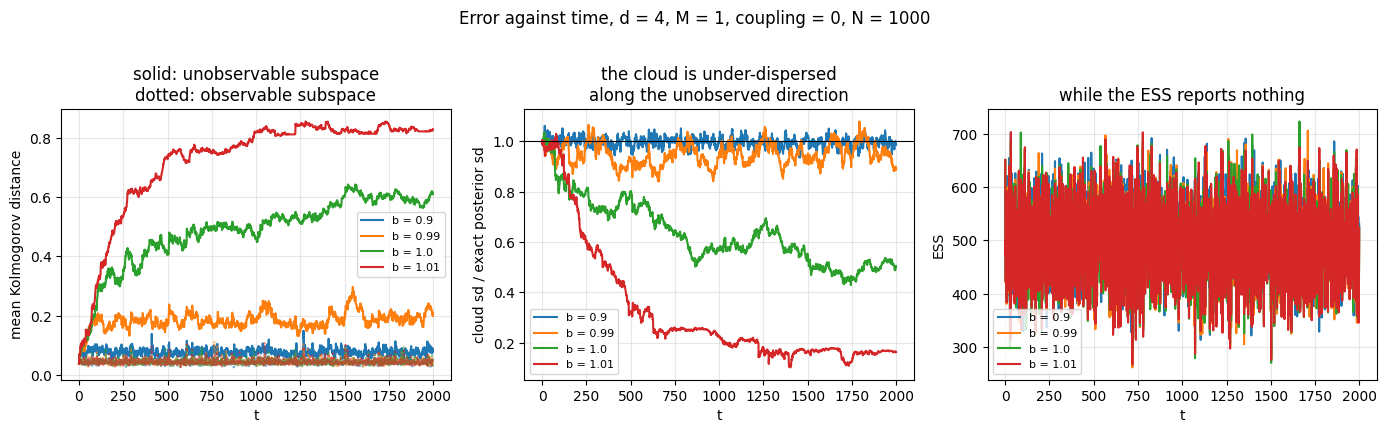

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for b, col in zip(BS_LONG, ("C0", "C1", "C2", "C3")):
    tt = np.arange(T_LONG)
    axes[0].plot(tt, traj[b][0], color=col, label=f"b = {b}")
    axes[0].plot(tt, traj[b][1], color=col, ls=":", alpha=0.6)
    axes[1].plot(tt, traj[b][2], color=col, label=f"b = {b}")
    axes[2].plot(tt, traj[b][4], color=col, label=f"b = {b}")
axes[0].set_ylabel("mean Kolmogorov distance")
axes[0].set_title("solid: unobservable subspace\ndotted: observable subspace")
axes[1].axhline(1.0, color="k", lw=0.8)
axes[1].set_ylabel("cloud sd / exact posterior sd")
axes[1].set_title("the cloud is under-dispersed\nalong the unobserved direction")
axes[2].set_ylabel("ESS")
axes[2].set_title("while the ESS reports nothing")
for ax in axes:
    ax.set_xlabel("t"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f"Error against time, d = 4, M = 1, coupling = 0, N = {N_PF}", y=1.02)
plt.tight_layout()
plt.show()

**Conclusion of Section 8.** **This is the first failure of time-uniform stability anywhere in this
project, and it is not a numerical artefact.**

In the unobservable subspace the Kolmogorov distance grows without bound:

| $b$ | $t = 0$ | $t = 199$ | $t = 1999$ | half-run ratio |
|---|---|---|---|---|
| 0.9 | 0.0379 | 0.0669 | 0.0814 | 1.003 |
| 0.99 | 0.0379 | 0.1685 | 0.1995 | 1.096 |
| 1.0 | 0.0379 | 0.3389 | 0.6099 | 1.405 |
| 1.01 | 0.0379 | 0.4816 | 0.8290 | 1.331 |

while in the **observable** subspace of the very same runs it is flat — $0.040$ to $0.045$ at every
$t$ and every $b$, exactly as Parts 3, 5 and 6 found. The stable cases act as their own control:
$b = 0.9$ is flat to $0.3\%$ over $T = 2000$ and $b = 0.99$ saturates near $0.19$. The threshold is
the dividing line, and it is the same line that divides bounded from unbounded posteriors.

$b = 1.0$ is the cell that settles it. There the state is a random walk of size $\sqrt{T} \approx
45$ and $b^T = 1$ exactly, so there is **no floating-point question of any kind** — none of Part 5
Section 8's cancellation applies — and the distance still goes from $0.038$ to $0.610$. The
divergence is in the inference problem, not in the arithmetic.

**The mechanism is measured, not inferred.** The particle cloud becomes progressively
**under-dispersed** along the unobserved direction: its spread, as a fraction of the spread the exact
posterior has there, falls $1.00 \to 0.81 \to 0.57 \to 0.50$ at $b = 1.0$, and to $0.16$ at
$b = 1.01$. At $b = 0.9$ it stays at $0.99$–$1.01$ throughout. The cloud is not wrong about where the
state is so much as too narrow about how little it knows, and the error in the posterior mean follows
to $0.62$ posterior standard deviations. The cause is resampling: weights are computed from the
observed coordinates alone, so every resampling event prunes diversity in a direction that carries
no information to justify the pruning, and when the true spread is growing there is nothing to
restore it. Where the posterior is bounded, the prior's pull replaces what resampling removes; above
the threshold it cannot keep up.

**And the standard diagnostic reports nothing.** The ESS sits at $500$–$650$ out of $1000$ in all
four runs, with no trend and no difference between $b = 0.9$ and $b = 1.01$. A practitioner watching
ESS would see a healthy filter at every step of a run whose error had grown twenty-fold. This
sharpens Part 5's observation that the ESS stayed at 50–65 while the posterior diverged: the ESS is
blind here not because the filter is fine but because it only ever measures the directions the
likelihood touches.

### Section 8b — more particles, and the numerical limit at $b = 1.1$

Two checks. First, whether the growth in $t$ is a bias that more particles cannot fix, or a large
constant in front of the usual $N^{-1/2}$: a slope near $-0.5$ in $\log N$ says the latter. Second,
what happens if Part 5's horizon limit is ignored and $b = 1.1$ is run to $T = 2000$ anyway — the
cell is reported, not hidden, because the failure is instructive and would be easy to mistake for a
result.

In [16]:
print(f"N-scaling of the unobservable-subspace KS at t = {min(149, T_PF-1)}, b = 1.0, d=4, M=1")
NS = (250, 1000, 4000, 16000) if not QUICK else (100, 400)
vals = []
for N in NS:
    ku, su, ko, so, es, k = pf_cell(4, 1, 1.0, 0.0, N=N, T=T_PF,
                                    seeds=range(4) if not QUICK else range(2))
    vals.append(ku)
    print(f"  N = {N:>6}: KS unobs {ku:.4f} +- {su:.4f}   KS obs {ko:.4f}")
sl = np.polyfit(np.log(NS), np.log(vals), 1)[0]
print(f"  slope in log N: {sl:+.4f}   (-0.5 = plain Monte Carlo error, 0 = bias)")

print(f"\nb = 1.1 run to T = {T_LONG}, past Part 5's limit of b^T <= 1e10 "
      f"(here b^T = {1.1**T_LONG:.1e})")
ku, ko, sd, bi, es = pf_traj(4, 1, 1.1, 0.0, T=T_LONG, seeds=range(3) if not QUICK else range(1))
print(f"{'t':>6} {'KS unobs':>9} {'KS obs':>9} {'sd ratio':>9}  b^t")
for t in [t for t in (0, 99, 199, 299, 499, 999, T_LONG - 1) if t < T_LONG]:
    print(f"{t:>6} {ku[t]:>9.4f} {ko[t]:>9.4f} {sd[t]:>9.4f}  {1.1**(t+1):.1e}")

N-scaling of the unobservable-subspace KS at t = 149, b = 1.0, d=4, M=1


  N =    250: KS unobs 0.3272 +- 0.0211   KS obs 0.0865


  N =   1000: KS unobs 0.1885 +- 0.0344   KS obs 0.0434


  N =   4000: KS unobs 0.0975 +- 0.0082   KS obs 0.0224


  N =  16000: KS unobs 0.0572 +- 0.0025   KS obs 0.0114
  slope in log N: -0.4251   (-0.5 = plain Monte Carlo error, 0 = bias)

b = 1.1 run to T = 2000, past Part 5's limit of b^T <= 1e10 (here b^T = 6.1e+82)


     t  KS unobs    KS obs  sd ratio  b^t
     0    0.0347    0.0384    1.0079  1.1e+00
    99    0.4502    0.0393    1.0082  1.4e+04
   199    0.7142    0.0425    0.6144  1.9e+08
   299    0.7671    0.0412    0.5213  2.6e+12
   499    0.7288    0.5000    0.6362  5.0e+20
   999    0.7288    0.5000    0.6362  2.5e+41
  1999    0.7288    0.5000    0.6362  6.1e+82


**Conclusion of Section 8b.** Two findings, one reassuring and one cautionary.

**More particles still help, at nearly the usual rate.** At fixed $t = 149$ the
unobservable-subspace distance falls $0.327 \to 0.189 \to 0.098 \to 0.057$ over $N = 250$ to
$16000$, a slope of $-0.425$ in $\log N$ against the $-0.5$ of plain Monte Carlo error. So the
growth in $t$ is not a bias that no amount of computation can remove: it is a constant in front of
$N^{-1/2}$ that itself grows with $t$. For any fixed horizon the filter is consistent; there is no
$N$ that makes it uniformly accurate over an unbounded one.

**And the $b = 1.1$ cell shows exactly what Part 5's horizon limit protects against.** Run to
$T = 2000$, where $b^T = 6.1 \times 10^{82}$, the two distances **freeze**: $0.7288$ and $0.5000$,
identically, from $t = 499$ to $t = 1999$, with the dispersion ratio stuck at $0.6362$. An error that
stops changing to four decimal places over fifteen hundred steps is not a result. The states have
passed the point where adding $O(1)$ process noise to a value of order $10^{20}$ changes anything, so
every particle's trajectory has become a deterministic multiple of its own past and the cloud has
frozen into a fixed shape. Note that the observable-subspace figure freezes at exactly $0.5000$ —
a suspiciously round number that is the signature of the arithmetic, not the filter. Reported here
rather than deleted, because it would be easy to present as saturation of a real effect: the honest
cells are $b = 1.0$ and $b = 1.01$, where the growth is unbounded and the arithmetic is exact.

---
## Section 9 — Is it a proposal problem?

Next-steps item 10 asked this directly:

> Part 3's rescue fixes the large-$M$ collapse. Part 5 Section 9 suggests the optimal proposal would
> *not* help with unbounded posterior uncertainty, since that is not a proposal problem — a clean
> negative result if confirmed.

The locally optimal proposal looks at $y_t$ before moving the particles. In the unobservable
subspace there is nothing to look at: the proposal and the prior transition coincide there by
construction, so it cannot place particles better. If the reasoning in Section 8 is right it should
improve the observable subspace and leave the unobservable one alone.

In [17]:
print(f"bootstrap against locally optimal, b = 1.1, T = {T_PF}, N = {N_PF}\n")
print(f"{'d':>2} {'M':>2} {'c':>4} | {'boot unobs':>10} {'opt unobs':>10} {'gain':>6} "
      f"| {'boot obs':>9} {'opt obs':>9} {'gain':>6}")
prop_rows = []
for d in DIMS:
    for c in COUPS:
        for M in range(1, d + 1):
            a = pf_cell(d, M, 1.1, c, prop="bootstrap")
            b_ = pf_cell(d, M, 1.1, c, prop="optimal")
            gu = a[0] / b_[0] if a[0] > 0 else np.nan
            go = a[2] / b_[2]
            prop_rows.append(dict(d=d, M=M, c=c, bu=a[0], ou=b_[0], bo=a[2], oo=b_[2],
                                  gu=gu, go=go, kdim=a[5]))
            uu = "  -" if np.isnan(a[0]) else f"{a[0]:.4f}"
            oo = "  -" if np.isnan(b_[0]) else f"{b_[0]:.4f}"
            gg = "  -" if np.isnan(gu) else f"{gu:.2f}"
            print(f"{d:>2} {M:>2} {c:>4} | {uu:>10} {oo:>10} {gg:>6} "
                  f"| {a[2]:>9.4f} {b_[2]:>9.4f} {go:>6.2f}")

gu = np.array([r["gu"] for r in prop_rows if r["kdim"] > 0])
go_un = np.array([r["go"] for r in prop_rows if r["kdim"] > 0])
go_de = np.array([r["go"] for r in prop_rows if r["kdim"] == 0])
print(f"\nunobservable subspace: gain {np.nanmean(gu):.2f}x "
      f"(range {np.nanmin(gu):.2f}-{np.nanmax(gu):.2f}) over {len(gu)} cells")
print(f"observable subspace, same cells: gain {np.nanmean(go_un):.2f}x")
print(f"observable subspace, detectable cells: gain {np.nanmean(go_de):.2f}x "
      f"(range {np.nanmin(go_de):.2f}-{np.nanmax(go_de):.2f})")

print(f"\nand over the long horizon, b = 1.0, d = 4, M = 1, T = {T_LONG}:")
ku_o, ko_o, sd_o, bi_o, es_o = pf_traj(4, 1, 1.0, 0.0, prop="optimal",
                                       seeds=range(4) if not QUICK else range(2))
print(f"{'t':>6} {'boot unobs':>10} {'opt unobs':>10} | {'boot sd':>8} {'opt sd':>8}")
for t in ts:
    print(f"{t:>6} {traj[1.0][0][t]:>10.4f} {ku_o[t]:>10.4f} | "
          f"{traj[1.0][2][t]:>8.4f} {sd_o[t]:>8.4f}")

bootstrap against locally optimal, b = 1.1, T = 150, N = 1000

 d  M    c | boot unobs  opt unobs   gain |  boot obs   opt obs   gain


 2  1  0.0 |     0.3017     0.1626   1.86 |    0.0452    0.0367   1.23


 2  2  0.0 |          -          -      - |    0.0749    0.0489   1.53


 2  1  0.2 |          -          -      - |    0.0606    0.0475   1.28


 2  2  0.2 |          -          -      - |    0.0711    0.0444   1.60


 4  1  0.0 |     0.2985     0.2034   1.47 |    0.0452    0.0361   1.25


... (20 outputs left out)

 8  6  0.2 |          -          -      - |    0.3494    0.1063   3.29


 8  7  0.2 |          -          -      - |    0.3335    0.0876   3.81


 8  8  0.2 |          -          -      - |    0.3556    0.0839   4.24

unobservable subspace: gain 1.52x (range 1.15-2.21) over 11 cells
observable subspace, same cells: gain 2.00x
observable subspace, detectable cells: gain 2.51x (range 1.28-4.24)

and over the long horizon, b = 1.0, d = 4, M = 1, T = 2000:


     t boot unobs  opt unobs |  boot sd   opt sd
     0     0.0379     0.0320 |   0.9978   1.0076
     9     0.0680     0.0556 |   1.0130   0.9808
    49     0.1179     0.0673 |   0.9579   1.0183
   199     0.3389     0.1363 |   0.8054   1.1010
   499     0.4183     0.2224 |   0.7953   0.9112
   999     0.4630     0.2613 |   0.5705   0.8810
  1499     0.6021     0.3456 |   0.5542   0.7980
  1999     0.6099     0.4734 |   0.5049   0.7890


**Conclusion of Section 9.** Next-steps item 10 is answered, and the answer is a **qualified no** —
closer to the conjecture than to a clean negative.

Over the 11 undetectable cells the locally optimal proposal improves the unobservable subspace by
$1.52\times$ on average (range $1.15$–$2.21$), against $2.00\times$ for the observable subspace of
the same cells and $2.51\times$ (up to $4.24\times$) for the detectable cells. So it helps least
exactly where the posterior is unbounded, which is the shape the conjecture predicted. The reason is
structural: in the unobservable subspace $p(x_t \mid x_{t-1}, y_t) = p(x_t \mid x_{t-1})$ by
definition, so the two proposals **coincide there**. What the optimal proposal buys is indirect — by
keeping weights even it resamples less, and resampling is what destroys the diversity Section 8
identified.

Indirect is not nothing, and the long run shows the limit of it. At $b = 1.0$, $T = 2000$ the optimal
proposal roughly halves the error ($0.610 \to 0.473$) and holds the dispersion ratio at $0.789$
instead of $0.505$. But both are still **growing** at $T = 2000$, and the ratio is still falling. The
proposal delays the failure by a constant factor; it does not remove it, and no proposal can, because
the quantity being approximated is itself unbounded. That is the sense in which Part 5's reading was
right: this is not a proposal problem. It is also not purely a posterior problem — Section 8 shows the
filter's error grows faster than the posterior's own uncertainty, which is a genuine algorithmic
failure on top of an ill-posed question.

---
## Section 10 — Summary

Part 5 Section 9 found a single case where the posterior itself diverged, and the repo's next-steps
list proposed mapping the boundary by sweeping $M$ from 1 to $d$. The sweep was run. **The premise
was wrong, in a way that is worth more than the curve would have been.**

### The question has no answer in $M$

At $\text{coupling} = 0$, every cell with $M < d$ diverges and every cell with $M = d$ is bounded,
with nothing between them — and the diverging cells report the *same* $\lambda_{\max}(P_T) = 6.1934
\times 10^{33}$ at every $d$ and every $M$ from 1 to $d - 1$. Seven observations of an
eight-dimensional state are worth exactly as much as one. At $\text{coupling} = 0.2$ the cliff is
gone and $M = 1$ suffices at every $d$ tested. The same sweep answers "all of them" and "one" for
reasons the question never mentions.

### What does decide it, exactly

Detectability: every eigenvalue of $F$ with $|\lambda| \ge 1$ must be observable. The Hautus test
agreed with the measured covariance recursion in **84 of 84 cells**, and `detectable` in
`filters.py` now computes it from $(F, H)$ in microseconds. When it fails, the posterior variance
grows at exactly $2 \log b$ — to $0.00 \times 10^0$ at $b = 1.1$, and linearly as
$\lambda_{\max}(P_t) = 1.0000\,t$ at $b = 1$, which is why the verdict has to be read from two
horizons rather than from a fitted geometric rate.

The cliff belongs to $F$, not to $H$: at $\text{coupling} = 0$, $HF^k = b^k H$, so the observability
rank is $\operatorname{rank} H$ whatever $H$ is, and a dense random $H$ reproduces $6.1934 \times
10^{33}$ at every $M < d$.

### The boundary is sharp in theory and blurred in arithmetic

Coupling is the real knob, and boundedness is discontinuous in it while the bound is not: as
$c \to 0$ at $d = 4$, $M = 1$ the posterior stays bounded while $\lambda_{\max}$ runs $20.7$ to
$2.4 \times 10^{14}$. $\sigma_{\min}(O)$ is a clean power law within a $d$ (exponent $-2.08$,
$-1.93$, $-1.89$) and fails across $d$ (pooled residual a factor of **706**) — reported as a
negative. More seriously, at $d = 8$ and $c \le 0.01$ the *numerical* rank drops below $d$ while the
mathematical rank is full, and the recursion diverges at a rate climbing towards $2 \log b$. **These
models are detectable and unfilterable.** A theorem resting on a rank gives no warning that the
information it relies on is carried at $10^{-23}$.

Where the posterior is bounded, each extra observation divides its spread by a roughly constant
factor — $2.7$ to $4.7$ at $c = 0.2$ — whose size is set by the coupling and is nearly independent
of $d$ ($-1.49$ at both $d = 8$ and $12$ for $c = 0.1$).

### What this costs the particle filter

Not what one would guess. Across detectable cells the posterior's spread varies by up to
$2839\times$ and the Kolmogorov distance by $1.78\times$; across cells with an *identical* posterior
the distance varies $2\times$ with $M$ and the ESS. At matched $M$ and matched ESS, undetectability
costs up to $5\times$ — but at $d = 8$ the sign reverses, and a **bounded** posterior with
$\lambda_{\max} = 1815$ is harder than an unbounded one, because an unobserved direction's posterior
*is* the prior propagation, which is exactly what the bootstrap proposal samples.

### The one result that changes a conclusion of this project

Parts 3, 5 and 6 all measured the error against $T$ and all found it flat — Part 6 to $T = 10^6$,
with a bounded metric. Every one of those runs was detectable. In the unobservable subspace the error
grows without bound: at $b = 1.0$, from $0.038$ to $0.610$ over $T = 2000$, half-run ratio $1.405$,
while the observable subspace of the same runs stays at $0.040$–$0.045$ and $b = 0.9$ is flat to
$0.3\%$. $b = 1.0$ has $b^T = 1$ exactly, so no floating-point reading of it is available.

The mechanism is measured: the cloud becomes **under-dispersed** along the unobserved direction,
its spread falling to $0.50$ of the posterior's at $b = 1.0$ and $0.16$ at $b = 1.01$, because
resampling prunes diversity using weights that carry no information about that direction, and above
the threshold the prior's pull cannot restore it. **The ESS reports nothing** — $500$–$650$ out of
$1000$, no trend, in all four runs.

More particles still help at nearly the Monte Carlo rate (slope $-0.425$ in $\log N$), so this is a
growing constant rather than a bias; and the locally optimal proposal improves the undetectable
cells by only $1.52\times$ against $2.51\times$ elsewhere, halving the long-run error without
stopping its growth. Item 10's conjecture was right in shape: no proposal can fix it, because the
object being approximated is itself unbounded.

### Limitations

1. **One family of $F$.** Everything rests on the symmetric tridiagonal base matrix of
   `build_model`, where coupling $\ne 0$ happens to make the first coordinate a cyclic vector and so
   makes $M = 1$ sufficient. That is a generic property, not a universal one; an $F$ whose unstable
   eigenvector is orthogonal to every power of $H$ would be undetectable at any $M < d$ with
   coupling present. The Hautus test handles such a case correctly — but no such case was *run*, so
   the 84/84 is an agreement over one structured family.
2. **$Q = R = I$ throughout**, as in Part 5. The bound's dependence on the noise levels is not
   mapped, and the geometric-in-$M$ decay of Section 6 may well be a statement about isotropic
   noise.
3. **The near-undetectable regime is only diagnosed, not measured.** Section 5 shows double
   precision losing the rank at $d = 8$, $c \le 0.01$, and reports the rate climbing — but a
   high-precision reference run, which would separate "the filter cannot use this information" from
   "this arithmetic cannot represent it", was not done.
4. **Section 8 uses one cell**, $d = 4$, $M = 1$, $\text{coupling} = 0$, over eight seeds. The
   growth is unmistakable there and the control at $b = 0.9$ and $0.99$ is clean, but the shape of
   the growth — whether it saturates at the Kolmogorov ceiling of 1, and at what $T$ — is not
   established, and $b = 1.1$ cannot be used to find out.
5. **No continuous detectability margin was found.** $\sigma_{\min}(O)$ fails across $d$; the natural
   next candidate is the information the data carry about the unstable eigenvector specifically, and
   a closed form for it was tried and discarded during this work because it under-predicted
   $\lambda_{\max}$ by factors of 3 to 80. That remains open.